# 02 — RDD, Spark SQL e PostgreSQL

Partiamo dai Parquet puliti del notebook 01. Calcoliamo le stesse metriche con RDD e Spark SQL, verifichiamo l'equivalenza, misuriamo i tempi e salviamo il run in PostgreSQL. La sessione Spark resta attiva fino alla verifica dell'export.

## 1. Input e metriche

I percorsi HDFS e l'identificativo del run provengono da `results/quality.json`. Raggruppiamo le corse per categoria (Yellow, Green, HVFHV), giorno della settimana (da lunedì a domenica) e fascia oraria di quattro ore del pickup.

| Metrica | Calcolo nel gruppo |
|---|---|
| Corse | Numero di corse valide |
| Ricavo totale (USD) | Somma delle tariffe base |
| Distanza media (mi) | Media delle distanze delle corse |
| Velocità media (mph) | Media delle velocità individuali delle corse |

In [1]:
import json
from collections import Counter
from datetime import datetime, timezone

from IPython.display import Image, Markdown, display

from src.aggregations import INPUT_COLUMNS, TOLERANCES, aggregate_rdd, aggregate_sql, compare
from src.benchmark import benchmark, save_benchmark
from src.config import INPUTS, RESULTS, save_json, spark_session
from src.postgresql import AGGREGATE_SCHEMA, export_run, read_artifacts


def avanza(messaggio):
    timestamp = datetime.now(timezone.utc).strftime("%H:%M:%S UTC")
    print(f"[{timestamp}] {messaggio}", flush=True)


def mostra_tabella(intestazioni, righe):
    tabella = [
        "| " + " | ".join(intestazioni) + " |",
        "| " + " | ".join("---" for _ in intestazioni) + " |",
    ]
    tabella.extend("| " + " | ".join(map(str, riga)) + " |" for riga in righe)
    display(Markdown("\n".join(tabella)))


def intero(valore):
    return f"{valore:,}".replace(",", ".")


def decimale(valore, cifre=2):
    return f"{valore:.{cifre}f}".replace(".", ",")


nomi_categorie = {"yellow": "Yellow", "green": "Green", "hvfhv": "HVFHV"}
nomi_algoritmi = {"rdd": "RDD", "sql": "Spark SQL"}
giorni = ("Lunedì", "Martedì", "Mercoledì", "Giovedì", "Venerdì", "Sabato", "Domenica")

quality = json.loads((RESULTS / "quality.json").read_text(encoding="utf-8"))
run_id = quality["run_id"]
aggregate_path = RESULTS / "aggregates.json"
aggregate_path.unlink(missing_ok=True)

avanza(f"Avvio Spark e apertura dei Parquet HDFS per il run {run_id}.")
spark = spark_session("TLC 02 - RDD, SQL e PostgreSQL")
frames = {
    category: spark.read.parquet(quality["categories"][category]["cleaned"]).select(*INPUT_COLUMNS)
    for category in INPUTS
}
common = frames["yellow"].unionByName(frames["green"]).unionByName(frames["hvfhv"])
avanza("Input comune preparato.")

[23:46:15 UTC] Avvio Spark e apertura dei Parquet HDFS per il run 20261120T222719Z-80fd1769.


26/11/20 23:46:17 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
                                                                                

[23:46:22 UTC] Input comune preparato.


## 2. Aggregazione RDD

`map` associa ogni corsa alla sua chiave e ai valori da sommare. `reduceByKey` combina somme e conteggi per chiave. Il risultato calcola le medie dividendo ciascuna somma per il numero di corse del gruppo.

In [2]:
avanza("Avvio aggregazione RDD.")
rdd_rows = aggregate_rdd(common)
avanza(f"RDD completato con {len(rdd_rows)} gruppi.")

[23:46:22 UTC] Avvio aggregazione RDD.


[Stage 3:====================================================>      (8 + 1) / 9]

[23:47:15 UTC] RDD completato con 126 gruppi.


## 3. Aggregazione Spark SQL

Registriamo lo stesso input come vista temporanea. La query usa `GROUP BY` sulle stesse chiavi e calcola `COUNT`, `SUM` e `AVG`. Entrambi i metodi raccolgono sul driver solo le righe aggregate.

In [3]:
avanza("Avvio aggregazione Spark SQL.")
sql_rows = aggregate_sql(common)
avanza(f"Spark SQL completato con {len(sql_rows)} gruppi.")

[23:47:15 UTC] Avvio aggregazione Spark SQL.


[Stage 5:====================================================>      (8 + 1) / 9]

[23:47:18 UTC] Spark SQL completato con 126 gruppi.


## 4. Equivalenza e risultati aggregati

Le chiavi di gruppo e i conteggi devono coincidere esattamente. Verifichiamo anche i totali per categoria rispetto al report di preprocessing. Per ricavo e medie la tolleranza relativa è 10⁻¹⁰. Le tolleranze assolute sono 10⁻⁶ USD per il ricavo e 10⁻⁹ per distanza e velocità.

Dopo il confronto mostriamo una tabella per categoria usando le righe SQL già raccolte. I risultati RDD equivalenti sono conservati insieme a quelli SQL per l'esportazione. L'arrotondamento delle tabelle è solo visivo.

In [4]:
avanza("Confronto dei gruppi e delle metriche.")
comparison = compare(rdd_rows, sql_rows)
actual = Counter()
for row in sql_rows:
    actual[row.vehicle_type] += row.trip_count
expected = {category: quality["categories"][category]["counts"]["valid_count"] for category in INPUTS}
if any(actual[category] != count for category, count in expected.items()) or actual.keys() - expected.keys():
    comparison["problems"].append(f"Conteggi HDFS {dict(actual)} diversi dal report {expected}")
    comparison["verdict"] = "FAIL"

massime = comparison["max_abs_difference"]
mostra_tabella(("Metrica", "Differenza assoluta massima"), [
    ("Ricavo totale (USD)", f"{massime['total_revenue']:.3g}"),
    ("Distanza media (mi)", f"{massime['avg_distance']:.3g}"),
    ("Velocità media (mph)", f"{massime['avg_speed']:.3g}"),
])
verdetto = comparison["verdict"]
avanza(f"Equivalenza {verdetto}. Gruppi RDD {comparison['groups_rdd']}, SQL {comparison['groups_sql']}.")
if verdetto != "PASS":
    raise RuntimeError("Verifica RDD/Spark SQL non superata. " + " | ".join(comparison["problems"]))

aggregate_report = {
    "run_id": run_id,
    "comparison": comparison,
    "tolerances": TOLERANCES,
    "rdd": [row.asDict() for row in rdd_rows],
    "sql": [row.asDict() for row in sql_rows],
}
save_json(aggregate_path, aggregate_report)

[23:47:18 UTC] Confronto dei gruppi e delle metriche.


| Metrica | Differenza assoluta massima |
| --- | --- |
| Ricavo totale (USD) | 0 |
| Distanza media (mi) | 0 |
| Velocità media (mph) | 0 |

[23:47:18 UTC] Equivalenza PASS. Gruppi RDD 126, SQL 126.


In [5]:
for categoria in INPUTS:
    display(Markdown(f"### {nomi_categorie[categoria]}"))
    mostra_tabella(
        ("Giorno", "Fascia oraria", "Corse", "Ricavo totale (USD)",
         "Distanza media (mi)", "Velocità media (mph)"),
        [(giorni[row.weekday - 1], row.time_slot, intero(row.trip_count),
          decimale(row.total_revenue), decimale(row.avg_distance), decimale(row.avg_speed))
         for row in sql_rows if row.vehicle_type == categoria],
    )

### Yellow

| Giorno | Fascia oraria | Corse | Ricavo totale (USD) | Distanza media (mi) | Velocità media (mph) |
| --- | --- | --- | --- | --- | --- |
| Lunedì | 00-04 | 18.688 | 549639,27 | 6,89 | 21,60 |
| Lunedì | 04-08 | 30.046 | 676562,79 | 4,83 | 15,65 |
| Lunedì | 08-12 | 81.759 | 1627702,71 | 3,49 | 10,56 |
| Lunedì | 12-16 | 95.865 | 1984333,42 | 3,61 | 10,06 |
| Lunedì | 16-20 | 108.853 | 2132031,54 | 3,32 | 10,30 |
| Lunedì | 20-24 | 85.499 | 1821806,72 | 4,08 | 13,63 |
| Martedì | 00-04 | 19.266 | 553804,15 | 6,70 | 20,56 |
| Martedì | 04-08 | 37.073 | 773226,43 | 4,36 | 14,69 |
| Martedì | 08-12 | 114.996 | 2287819,05 | 3,12 | 9,14 |
| Martedì | 12-16 | 134.055 | 2721896,76 | 3,23 | 8,86 |
| Martedì | 16-20 | 154.688 | 2865347,41 | 2,93 | 9,36 |
| Martedì | 20-24 | 131.049 | 2538902,30 | 3,56 | 12,67 |
| Mercoledì | 00-04 | 22.258 | 563875,35 | 5,71 | 18,40 |
| Mercoledì | 04-08 | 38.408 | 783020,46 | 4,20 | 14,41 |
| Mercoledì | 08-12 | 116.501 | 2276615,27 | 3,05 | 9,19 |
| Mercoledì | 12-16 | 133.278 | 2728328,54 | 3,22 | 8,71 |
| Mercoledì | 16-20 | 149.927 | 2858308,64 | 2,96 | 9,06 |
| Mercoledì | 20-24 | 137.220 | 2644104,29 | 3,55 | 12,37 |
| Giovedì | 00-04 | 27.897 | 606912,66 | 4,71 | 16,60 |
| Giovedì | 04-08 | 37.618 | 795109,40 | 4,45 | 14,92 |
| Giovedì | 08-12 | 112.049 | 2218642,64 | 3,16 | 9,32 |
| Giovedì | 12-16 | 139.298 | 2960823,66 | 3,27 | 8,53 |
| Giovedì | 16-20 | 138.394 | 2837102,54 | 3,13 | 8,93 |
| Giovedì | 20-24 | 130.866 | 2623803,80 | 3,71 | 12,35 |
| Venerdì | 00-04 | 34.885 | 731886,06 | 4,44 | 15,91 |
| Venerdì | 04-08 | 25.201 | 564712,70 | 4,89 | 16,57 |
| Venerdì | 08-12 | 66.619 | 1293927,58 | 3,48 | 11,26 |
| Venerdì | 12-16 | 96.940 | 2002103,25 | 3,51 | 10,25 |
| Venerdì | 16-20 | 99.172 | 1956165,29 | 3,31 | 10,30 |
| Venerdì | 20-24 | 101.023 | 2069263,03 | 3,77 | 12,03 |
| Sabato | 00-04 | 70.079 | 1394517,93 | 3,78 | 13,78 |
| Sabato | 04-08 | 21.009 | 495214,31 | 5,20 | 18,80 |
| Sabato | 08-12 | 57.870 | 1109019,01 | 3,69 | 13,31 |
| Sabato | 12-16 | 96.180 | 1956766,24 | 3,62 | 11,36 |
| Sabato | 16-20 | 111.489 | 2293114,97 | 3,56 | 10,89 |
| Sabato | 20-24 | 102.696 | 2127790,77 | 3,80 | 12,01 |
| Domenica | 00-04 | 72.454 | 1444429,63 | 3,80 | 13,95 |
| Domenica | 04-08 | 22.128 | 544305,77 | 5,44 | 19,67 |
| Domenica | 08-12 | 55.125 | 1093157,66 | 4,01 | 14,93 |
| Domenica | 12-16 | 96.269 | 2044140,40 | 3,96 | 12,11 |
| Domenica | 16-20 | 95.680 | 2038160,39 | 4,03 | 12,18 |
| Domenica | 20-24 | 73.471 | 1728273,46 | 4,94 | 15,16 |

### Green

| Giorno | Fascia oraria | Corse | Ricavo totale (USD) | Distanza media (mi) | Velocità media (mph) |
| --- | --- | --- | --- | --- | --- |
| Lunedì | 00-04 | 162 | 3808,14 | 4,18 | 17,31 |
| Lunedì | 04-08 | 520 | 8240,00 | 4,15 | 14,75 |
| Lunedì | 08-12 | 1.514 | 25657,78 | 3,39 | 11,07 |
| Lunedì | 12-16 | 1.512 | 24393,15 | 3,27 | 10,76 |
| Lunedì | 16-20 | 1.842 | 27938,05 | 2,75 | 10,99 |
| Lunedì | 20-24 | 778 | 16497,54 | 3,63 | 14,08 |
| Martedì | 00-04 | 159 | 3099,78 | 4,13 | 17,29 |
| Martedì | 04-08 | 600 | 9895,55 | 4,39 | 14,11 |
| Martedì | 08-12 | 2.051 | 36563,25 | 3,45 | 10,94 |
| Martedì | 12-16 | 1.913 | 31673,67 | 3,31 | 10,44 |
| Martedì | 16-20 | 2.243 | 34644,18 | 2,66 | 10,78 |
| Martedì | 20-24 | 1.065 | 22934,91 | 3,68 | 14,05 |
| Mercoledì | 00-04 | 180 | 3262,70 | 3,78 | 15,80 |
| Mercoledì | 04-08 | 540 | 8988,84 | 4,35 | 14,60 |
| Mercoledì | 08-12 | 1.893 | 30809,93 | 3,08 | 10,87 |
| Mercoledì | 12-16 | 1.922 | 32026,53 | 3,27 | 10,40 |
| Mercoledì | 16-20 | 2.339 | 37536,43 | 2,86 | 10,94 |
| Mercoledì | 20-24 | 1.121 | 25191,43 | 3,73 | 13,60 |
| Giovedì | 00-04 | 211 | 3844,82 | 3,80 | 15,71 |
| Giovedì | 04-08 | 518 | 7532,30 | 4,33 | 14,66 |
| Giovedì | 08-12 | 1.871 | 30257,99 | 3,14 | 10,69 |
| Giovedì | 12-16 | 2.121 | 36648,18 | 3,31 | 10,19 |
| Giovedì | 16-20 | 2.359 | 39889,96 | 2,89 | 10,22 |
| Giovedì | 20-24 | 1.043 | 20719,16 | 3,42 | 13,08 |
| Venerdì | 00-04 | 199 | 4112,48 | 3,89 | 16,06 |
| Venerdì | 04-08 | 346 | 5646,59 | 4,49 | 15,92 |
| Venerdì | 08-12 | 1.068 | 17025,92 | 3,46 | 12,25 |
| Venerdì | 12-16 | 1.273 | 21232,86 | 3,31 | 11,57 |
| Venerdì | 16-20 | 1.609 | 26923,95 | 3,00 | 10,90 |
| Venerdì | 20-24 | 998 | 24314,41 | 3,96 | 13,13 |
| Sabato | 00-04 | 478 | 13458,96 | 4,29 | 15,66 |
| Sabato | 04-08 | 243 | 7074,65 | 4,74 | 18,84 |
| Sabato | 08-12 | 707 | 11844,29 | 3,98 | 14,05 |
| Sabato | 12-16 | 1.168 | 20959,36 | 3,53 | 11,65 |
| Sabato | 16-20 | 1.410 | 26286,30 | 3,47 | 11,64 |
| Sabato | 20-24 | 1.015 | 22765,70 | 3,88 | 13,18 |
| Domenica | 00-04 | 461 | 12471,96 | 4,22 | 15,04 |
| Domenica | 04-08 | 235 | 6803,27 | 5,19 | 18,91 |
| Domenica | 08-12 | 738 | 12356,69 | 4,27 | 14,77 |
| Domenica | 12-16 | 1.358 | 23170,38 | 3,36 | 12,51 |
| Domenica | 16-20 | 1.512 | 26988,17 | 3,27 | 12,49 |
| Domenica | 20-24 | 902 | 18811,65 | 3,65 | 14,01 |

### HVFHV

| Giorno | Fascia oraria | Corse | Ricavo totale (USD) | Distanza media (mi) | Velocità media (mph) |
| --- | --- | --- | --- | --- | --- |
| Lunedì | 00-04 | 177.170 | 4381018,56 | 6,15 | 18,47 |
| Lunedì | 04-08 | 265.287 | 7731818,14 | 6,33 | 17,59 |
| Lunedì | 08-12 | 481.744 | 12510085,19 | 4,85 | 12,96 |
| Lunedì | 12-16 | 433.067 | 12019293,38 | 5,01 | 12,30 |
| Lunedì | 16-20 | 515.110 | 13145573,71 | 4,42 | 12,06 |
| Lunedì | 20-24 | 418.459 | 11149472,50 | 5,38 | 15,17 |
| Martedì | 00-04 | 175.059 | 4469451,79 | 6,01 | 18,18 |
| Martedì | 04-08 | 324.159 | 8947639,13 | 5,94 | 16,86 |
| Martedì | 08-12 | 632.676 | 16806169,00 | 4,57 | 12,04 |
| Martedì | 12-16 | 572.833 | 15951264,84 | 4,75 | 11,62 |
| Martedì | 16-20 | 697.333 | 17893502,84 | 4,29 | 11,43 |
| Martedì | 20-24 | 589.900 | 16673672,86 | 5,44 | 14,90 |
| Mercoledì | 00-04 | 196.162 | 4856510,91 | 5,78 | 17,71 |
| Mercoledì | 04-08 | 336.630 | 9235869,21 | 5,87 | 16,67 |
| Mercoledì | 08-12 | 648.003 | 17238179,92 | 4,55 | 12,09 |
| Mercoledì | 12-16 | 582.388 | 16800383,92 | 4,85 | 11,54 |
| Mercoledì | 16-20 | 696.997 | 18665472,42 | 4,40 | 11,26 |
| Mercoledì | 20-24 | 620.191 | 17774666,56 | 5,56 | 14,71 |
| Giovedì | 00-04 | 226.974 | 5553380,90 | 5,66 | 17,26 |
| Giovedì | 04-08 | 347.112 | 9815805,63 | 6,12 | 17,09 |
| Giovedì | 08-12 | 661.642 | 17726265,40 | 4,67 | 12,17 |
| Giovedì | 12-16 | 629.515 | 19022662,33 | 4,85 | 11,00 |
| Giovedì | 16-20 | 732.159 | 20534560,79 | 4,46 | 10,78 |
| Giovedì | 20-24 | 658.338 | 18068613,84 | 5,46 | 14,33 |
| Venerdì | 00-04 | 242.671 | 6036993,13 | 5,68 | 16,92 |
| Venerdì | 04-08 | 258.510 | 7361365,21 | 6,42 | 18,29 |
| Venerdì | 08-12 | 457.960 | 11753397,30 | 5,02 | 13,56 |
| Venerdì | 12-16 | 492.429 | 13839927,01 | 4,99 | 12,15 |
| Venerdì | 16-20 | 611.887 | 15181341,77 | 4,56 | 12,09 |
| Venerdì | 20-24 | 618.205 | 15664283,16 | 4,99 | 13,61 |
| Sabato | 00-04 | 420.881 | 10818911,80 | 5,31 | 15,64 |
| Sabato | 04-08 | 225.050 | 6131028,97 | 6,53 | 19,52 |
| Sabato | 08-12 | 409.208 | 9913988,08 | 5,21 | 14,82 |
| Sabato | 12-16 | 531.879 | 13457276,95 | 4,92 | 12,77 |
| Sabato | 16-20 | 621.973 | 15269052,36 | 4,82 | 12,68 |
| Sabato | 20-24 | 637.540 | 15694806,03 | 5,01 | 13,70 |
| Domenica | 00-04 | 434.785 | 11105645,29 | 5,39 | 15,98 |
| Domenica | 04-08 | 217.392 | 6209141,82 | 6,79 | 20,31 |
| Domenica | 08-12 | 382.338 | 9234798,56 | 5,46 | 16,41 |
| Domenica | 12-16 | 502.678 | 13373360,43 | 5,22 | 13,52 |
| Domenica | 16-20 | 512.266 | 12811459,39 | 5,16 | 13,61 |
| Domenica | 20-24 | 453.424 | 11127381,19 | 5,47 | 15,17 |

### Visualizzazione dei risultati per giorno e fascia oraria

Si usano gli aggregati Spark SQL salvati in `results/aggregates.json` dopo la verifica di equivalenza. Per ogni metrica si usa una scala cromatica comune a Yellow, Green e HVFHV.

In [ ]:
from src.analytical_plots import generate_heatmaps

didascalie = (
    "**Figura 1.** Ricavo totale (USD). Si usa una scala cromatica logaritmica per distinguere le variazioni anche nelle categorie con ricavi minori.",
    "**Figura 2.** Distanza media (miglia per corsa) su scala cromatica lineare.",
    "**Figura 3.** Velocità media (mph) su scala cromatica lineare.",
)
for figura, didascalia in zip(generate_heatmaps(RESULTS), didascalie):
    display(Image(filename=str(figura), width=710))
    display(Markdown(didascalia))

## 5. Benchmark

Per Green, Yellow e HVFHV materializziamo lo stesso input su disco locale per entrambi i metodi, una categoria alla volta. Dopo un warm-up per metodo, misuriamo cinque coppie con ordine alternato.

Il cronometro comprende la scansione della cache, le trasformazioni, l'aggregazione, l'ordinamento e la raccolta delle righe aggregate. Preparazione della cache, preprocessing, scritture su HDFS, grafico ed export PostgreSQL sono fuori dalle misurazioni. I tempi descrivono questa macchina e dipendono anche da disco, CPU e RAM.

In [6]:
for name in ("benchmark.csv", "benchmark_summary.json", "benchmark.png"):
    (RESULTS / name).unlink(missing_ok=True)

avanza("Avvio del benchmark per Green, Yellow e HVFHV.")
timings, summary = benchmark(frames, run_id)
avanza(f"Benchmark completato con {len(timings)} misure.")
save_benchmark(timings, summary)

[23:47:18 UTC] Avvio del benchmark per Green, Yellow e HVFHV.


[23:52:56 UTC] Benchmark completato con 30 misure.


## 6. Statistiche e grafico del benchmark

La tabella riporta media, mediana e deviazione standard campionaria delle durate. Il rapporto divide la mediana RDD per quella Spark SQL. Un valore maggiore di 1 indica una mediana inferiore per Spark SQL. Il grafico confronta le mediane usando le misure appena salvate.

| Categoria | Metodo | Media (s) | Mediana (s) | Dev. std. campionaria (s) | Mediana RDD / SQL |
| --- | --- | --- | --- | --- | --- |
| Green | RDD | 0,416 | 0,391 | 0,060 | 1,89× |
| Green | Spark SQL | 0,234 | 0,207 | 0,076 | — |
| Yellow | RDD | 8,124 | 7,943 | 0,487 | 24,45× |
| Yellow | Spark SQL | 0,316 | 0,325 | 0,034 | — |
| HVFHV | RDD | 45,473 | 45,677 | 0,486 | 54,35× |
| HVFHV | Spark SQL | 0,844 | 0,840 | 0,040 | — |

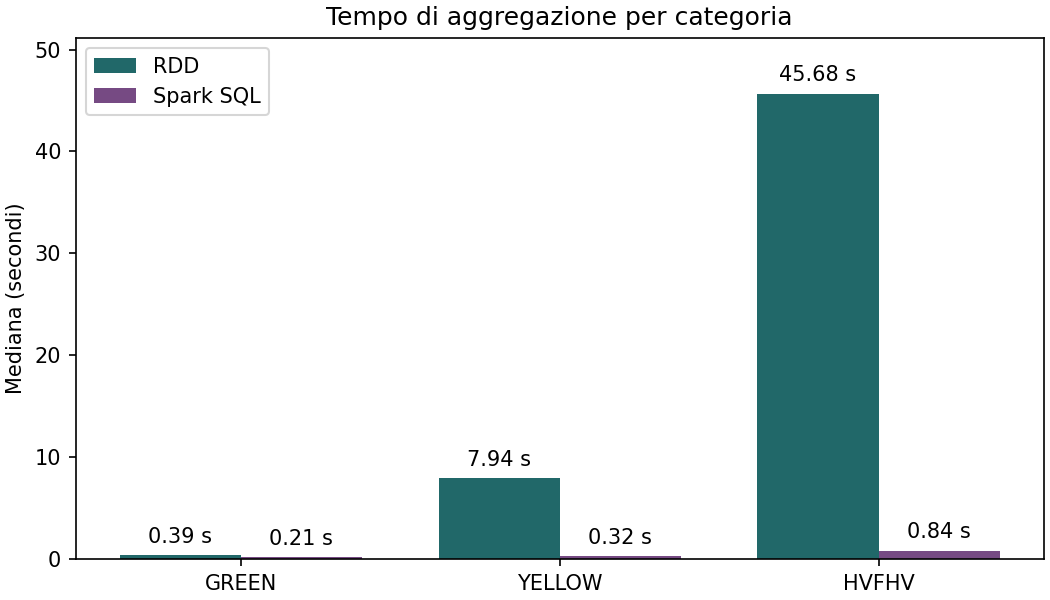

In [7]:
righe = []
for categoria, statistiche in summary.items():
    for algoritmo, metodo in nomi_algoritmi.items():
        valori = statistiche[algoritmo]
        rapporto = decimale(statistiche["speedup_rdd_over_sql"]) + "×" if algoritmo == "rdd" else "—"
        righe.append((
            nomi_categorie[categoria], metodo, decimale(valori["mean"], 3),
            decimale(valori["median"], 3), decimale(valori["stdev"], 3), rapporto,
        ))

mostra_tabella(
    ("Categoria", "Metodo", "Media (s)", "Mediana (s)", "Dev. std. campionaria (s)", "Mediana RDD / SQL"),
    righe,
)
display(Image(filename=str(RESULTS / "benchmark.png")))

## 7. Esportazione e verifica su PostgreSQL

Riprendiamo la tecnica del laboratorio 05, che usa JDBC per scrivere e rileggere DataFrame Spark. Qui usiamo PostgreSQL al posto di MySQL, con il driver PostgreSQL già incluso nel container. Il DataFrame contiene le righe di entrambi i metodi, distinti dalla colonna `algorithm`.

Il modulo `src.postgresql` crea con Psycopg una tabella di staging nello stesso schema. Spark scrive con `df.write.mode("append").jdbc(...)` e rilegge con `spark.read.jdbc(...)`, con una sola partizione JDBC. La rilettura controlla identificativo, categorie, algoritmi, gruppi e corse prima della pubblicazione. [Documentazione JDBC di Spark](https://archive.apache.org/dist/spark/docs/3.5.5/sql-data-sources-jdbc.html)

| Tabella PostgreSQL | Dati del run |
|---|---|
| `tlc_aggregates` | Aggregati RDD e Spark SQL |
| `tlc_benchmark` | Misurazioni individuali e configurazione del benchmark |
| `tlc_quality` | Report del preprocessing, inclusi conteggi e soglie |

Psycopg pubblica gli aggregati verificati nella tabella `tlc_aggregates` esistente, mantenendo chiave primaria e vincoli. Nella stessa transazione sostituisce le righe del `run_id`, salva qualità e tempi e verifica gruppi, corse e numero di misure prima del commit. Un errore JDBC lascia intatto il run precedente. Scrittura, rilettura e pubblicazione avvengono dopo il benchmark.

In [8]:
avanza("Caricamento dei report e avvio dell'export PostgreSQL.")
qualita_db, aggregati_db, misure_db = read_artifacts()
df_aggregati = spark.createDataFrame(
    [dict(riga, run_id=qualita_db["run_id"], algorithm=algoritmo)
     for algoritmo in ("rdd", "sql") for riga in aggregati_db[algoritmo]],
    schema=AGGREGATE_SCHEMA,
)
salvati = export_run(df_aggregati, qualita_db, aggregati_db, misure_db)
avanza(f"Export PostgreSQL verificato e salvato per il run {qualita_db['run_id']}.")

mostra_tabella(
    ("Categoria", "Metodo", "Gruppi salvati", "Corse rappresentate"),
    [(nomi_categorie[categoria], nomi_algoritmi[algoritmo], intero(gruppi), intero(corse))
     for categoria, algoritmo, gruppi, corse in salvati],
)

[23:52:57 UTC] Caricamento dei report e avvio dell'export PostgreSQL.


[23:52:58 UTC] Export PostgreSQL verificato e salvato per il run 20261120T222719Z-80fd1769.


| Categoria | Metodo | Gruppi salvati | Corse rappresentate |
| --- | --- | --- | --- |
| Green | RDD | 42 | 46.197 |
| Green | Spark SQL | 42 | 46.197 |
| HVFHV | RDD | 42 | 19.649.984 |
| HVFHV | Spark SQL | 42 | 19.649.984 |
| Yellow | RDD | 42 | 3.493.841 |
| Yellow | Spark SQL | 42 | 3.493.841 |

## 8. Chiusura della sessione Spark

Dopo la verifica PostgreSQL chiudiamo l'unica sessione Spark del notebook.

In [9]:
avanza("Chiusura della sessione Spark.")
spark.stop()

[23:52:58 UTC] Chiusura della sessione Spark.
